In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Cargar los datasets reales
df_train = pd.read_csv('../datasets/train.csv')
df_test = pd.read_csv('../datasets/test.csv')

print(f"Datos Históricos (Train): {df_train.shape[0]} equipos")
print(f"Datos Mundial 2026 (Test): {df_test.shape[0]} equipos")

# Elegimos las variables numéricas que alimentarán a las neuronas
features = [
    'fifa_rank_pre_tournament', 'fifa_points_pre_tournament', 
    'squad_total_market_value_eur', 'goals_scored_last_4y', 
    'wins_last_4y', 'squad_avg_age'
]

# Separamos las variables (X) y el objetivo (y)
# Usaremos 'quarter_finalist' (1 = Llegó a cuartos, 0 = No llegó)
X_historico = df_train[features]
y_historico = df_train['quarter_finalist']

# Rellenar valores nulos (La red neuronal no acepta NaNs)
X_historico = X_historico.fillna(X_historico.median())

Datos Históricos (Train): 192 equipos
Datos Mundial 2026 (Test): 48 equipos


In [9]:
# 2. Separar datos históricos para validar el modelo
X_train, X_val, y_train, y_val = train_test_split(X_historico, y_historico, test_size=0.2, random_state=42)

# 3. ESCALAR LOS DATOS (¡Paso obligatorio en Redes Neuronales!)
scaler = StandardScaler()

# Ajustamos el escalador con los datos de entrenamiento y transformamos
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("✅ Datos escalados correctamente. Las magnitudes ahora están equilibradas.")

✅ Datos escalados correctamente. Las magnitudes ahora están equilibradas.


Entrenando la Red Neuronal...
Precisión de la Red Neuronal: 74.4%


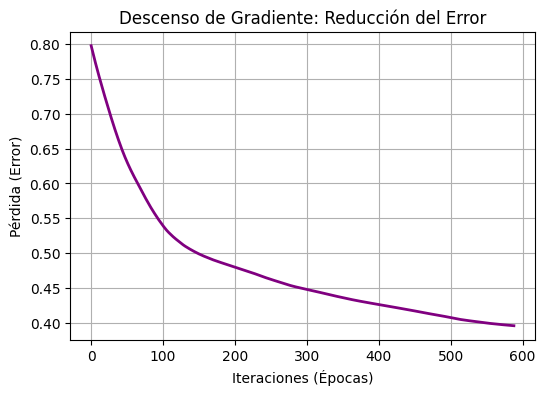

In [10]:
# 4. Diseñar la Red Neuronal
# hidden_layer_sizes=(10, 5): 10 neuronas en la 1ra capa oculta, 5 en la 2da.
# activation='relu': La función moderna recomendada para capas ocultas.
# max_iter=2000: Le damos hasta 2000 pasadas para que ajuste sus pesos.
red_neuronal = MLPClassifier(
    hidden_layer_sizes=(10, 5), 
    activation='relu', 
    solver='adam',      # Optimizador avanzado basado en descenso de gradiente
    max_iter=2000, 
    random_state=42
)

# 5. Entrenar el modelo (Forward y Backpropagation)
print("Entrenando la Red Neuronal...")
red_neuronal.fit(X_train_scaled, y_train)

# 6. Evaluación
y_pred_val = red_neuronal.predict(X_val_scaled)
precision = accuracy_score(y_val, y_pred_val)
print(f"Precisión de la Red Neuronal: {precision * 100:.1f}%")

# 7. Graficar la "Curva de Aprendizaje" (Descenso de Gradiente)
plt.figure(figsize=(6,4))
plt.plot(red_neuronal.loss_curve_, color='purple', linewidth=2)
plt.title("Descenso de Gradiente: Reducción del Error")
plt.xlabel("Iteraciones (Épocas)")
plt.ylabel("Pérdida (Error)")
plt.grid(True)
plt.show()

🏆 TOP 10 FAVORITOS PARA LLEGAR A CUARTOS DE FINAL (MUNDIAL 2026) 🏆


,team,Prob_Cuartos_Final_%
1,Spain,62.876812
0,France,60.161558
3,England,59.864633
4,Portugal,53.619030
6,Netherlands,44.124459
2,Argentina,39.508623
9,Germany,38.961277
12,Senegal,26.078810
5,Brazil,25.532750
8,Belgium,24.070272


C:\Users\magal\AppData\Local\Temp\ipykernel_17092\3978547803.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=favoritos_cuartos.head(10), x='Prob_Cuartos_Final_%', y='team', palette='viridis')


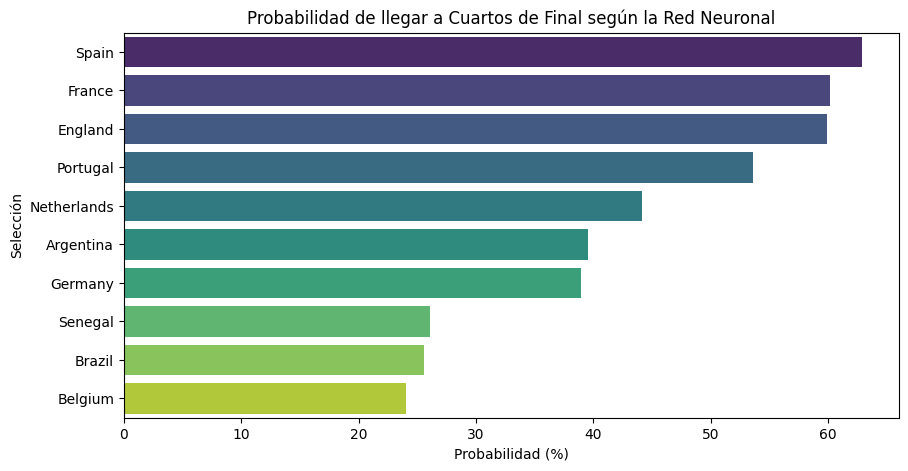

In [11]:
# 8. Preparar a los equipos del Mundial 2026
X_2026 = df_test[features].fillna(df_test[features].median())

# ¡IMPORTANTE! Aplicar exactamente el mismo escalador que aprendió en el Train
X_2026_scaled = scaler.transform(X_2026)

# 9. Calcular las probabilidades matemáticas
probabilidades = red_neuronal.predict_proba(X_2026_scaled)[:, 1]

# 10. Agregar las probabilidades al DataFrame y mostrar el Top 10
df_test['Prob_Cuartos_Final_%'] = probabilidades * 100
favoritos_cuartos = df_test[['team', 'Prob_Cuartos_Final_%']].sort_values(by='Prob_Cuartos_Final_%', ascending=False)

print("🏆 TOP 10 FAVORITOS PARA LLEGAR A CUARTOS DE FINAL (MUNDIAL 2026) 🏆")
display(favoritos_cuartos.head(10))

# Visualización para la gerencia
plt.figure(figsize=(10,5))
sns.barplot(data=favoritos_cuartos.head(10), x='Prob_Cuartos_Final_%', y='team', palette='viridis')
plt.title("Probabilidad de llegar a Cuartos de Final según la Red Neuronal")
plt.xlabel("Probabilidad (%)")
plt.ylabel("Selección")
plt.show()

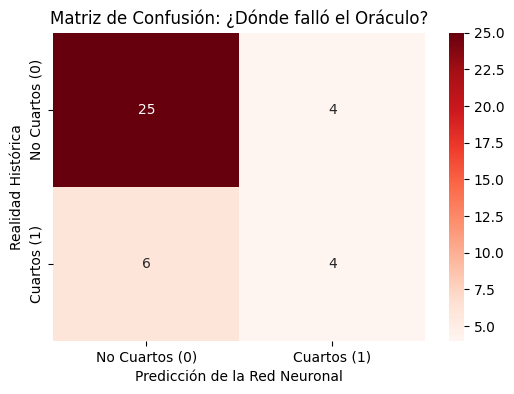


❌ LOS 'ROMPEAPUESTAS': Equipos históricos que engañaron a la Red Neuronal


,Equipo,Mundial,Llegó_a_Cuartos_Realmente,Predicción_de_la_IA
136,Colombia,2014,Sí,No
76,Germany,2022,No,Sí
30,Ukraine,2006,Sí,No
171,Germany,2002,Sí,No
118,Portugal,2010,No,Sí
24,Spain,2006,No,Sí
60,Sweden,2018,Sí,No
141,France,2014,Sí,No
90,Spain,2022,No,Sí
133,Brazil,2014,Sí,No


In [12]:
# --- ANÁLISIS DE ERRORES (MATRIZ DE CONFUSIÓN) ---
from sklearn.metrics import confusion_matrix

# 1. Graficar la Matriz de Confusión
cm = confusion_matrix(y_val, y_pred_val)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=['No Cuartos (0)', 'Cuartos (1)'], 
            yticklabels=['No Cuartos (0)', 'Cuartos (1)'])
plt.title("Matriz de Confusión: ¿Dónde falló el Oráculo?")
plt.ylabel('Realidad Histórica')
plt.xlabel('Predicción de la Red Neuronal')
plt.show()

# 2. Descubrir exactamente qué equipos confundieron a la Red
y_pred_series = pd.Series(y_pred_val, index=y_val.index)

# Filtramos los índices de los errores
indices_errores = y_val[y_val != y_pred_series].index

# Armamos el DataFrame comparativo
errores_df = pd.DataFrame({
    'Equipo': df_train.loc[indices_errores, 'team'],
    'Mundial': df_train.loc[indices_errores, 'version'],
    'Llegó_a_Cuartos_Realmente': y_val[indices_errores],
    'Predicción_de_la_IA': y_pred_series[indices_errores] # Ahora usamos la Serie corregida
})

# Reemplazamos los 0 y 1 con texto para que sea más legible
errores_df = errores_df.replace({0: 'No', 1: 'Sí'})

print("\n❌ LOS 'ROMPEAPUESTAS': Equipos históricos que engañaron a la Red Neuronal")
display(errores_df)